Cell 1: Select GPU

In [ ]:
!nvidia-smi
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

Sat Oct 24 22:10:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Cell 2: Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_ROOT = "/content/drive/MyDrive/EO_IR_Capstone"
assert os.path.isdir(DRIVE_ROOT), f"Not found: {DRIVE_ROOT} (check shortcut name/permissions)"
print(os.listdir(DRIVE_ROOT))

Mounted at /content/drive
['data', 'runs', 'evidence', 'poster']


Cell 3: Get the Team Code

In [ ]:
from google.colab import userdata
import subprocess

REPO_OWNER = "Carlsonjacob2004"   # fill in the real value before committing
REPO_NAME  = "EO_IR_Capstone"         # fill in the real value
REPO_DIR   = f"/content/{REPO_NAME}"

token = userdata.get("GITHUB_TOKEN")
if not os.path.isdir(REPO_DIR):
    url = f"https://{token}@github.com/{REPO_OWNER}/{REPO_NAME}.git"
    r = subprocess.run(["git", "clone", "-q", url, REPO_DIR], capture_output=True, text=True)
else:
    r = subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], capture_output=True, text=True)
print("OK" if r.returncode == 0 else r.stderr.replace(token, "***"))

OK


Cell 4: Intall the Detector

In [ ]:
YOLO_DIR    = "/content/yolov5"
YOLO_COMMIT = "f9578796b8a64889aa9e66dc06914d19f40d338e"   # paste the tested commit hash here (see below)

if not os.path.isdir(YOLO_DIR):
    !git clone -q https://github.com/ultralytics/yolov5.git {YOLO_DIR}
if YOLO_COMMIT:
    !git -C {YOLO_DIR} checkout -q {YOLO_COMMIT}
!pip install -q -r {YOLO_DIR}/requirements.txt
!git -C {YOLO_DIR} rev-parse HEAD

f9578796b8a64889aa9e66dc06914d19f40d338e


Cell 5: Smoke test with pretrained weights

/content/yolov5
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
detect: weights=['yolov5s.pt'], source=data/images/bus.jpg, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=/content/smoke, name=pretrained, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

100% 14.1M/14.1M [00:00<00:00, 469MB/s]

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients,

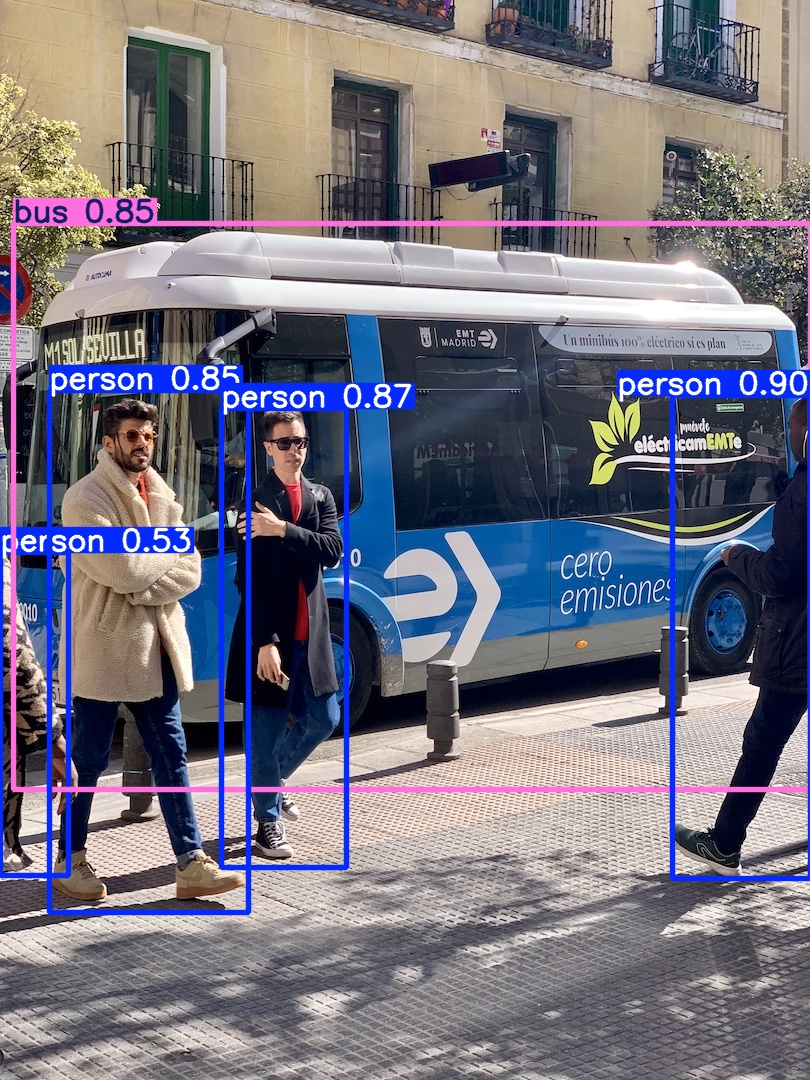

In [ ]:
%cd {YOLO_DIR}
!python detect.py --weights yolov5s.pt --source data/images/bus.jpg --img 640 \
    --project /content/smoke --name pretrained --exist-ok
from IPython.display import Image, display
display(Image("/content/smoke/pretrained/bus.jpg"))

Cell 6: Record versions

In [ ]:
import sys, platform, torchvision, numpy, cv2
yolo_hash = subprocess.check_output(["git", "-C", YOLO_DIR, "rev-parse", "HEAD"]).decode().strip()
info = f"""python {sys.version.split()[0]}
torch {torch.__version__} (CUDA {torch.version.cuda})
torchvision {torchvision.__version__}
numpy {numpy.__version__}
opencv {cv2.__version__}
gpu {torch.cuda.get_device_name(0)}
yolov5 commit {yolo_hash}
"""
print(info)
open("/content/versions.txt", "w").write(info)
!pip freeze > /content/pip_freeze.txt

python 3.13.16
torch 2.11.0+cu130 (CUDA 13.0)
torchvision 0.26.0+cu130
numpy 2.1.3
opencv 4.14.0
gpu Tesla T4
yolov5 commit f9578796b8a64889aa9e66dc06914d19f40d338e



In [ ]:
from pathlib import Path
import shutil
import zipfile

shared_root = Path("/content/drive/MyDrive/EO_IR_Capstone")
source = shared_root / "data/raw/LLVIP.zip"

work = Path("/content/eo_ir_recovery")
work.mkdir(parents=True, exist_ok=True)
local_archive = work / "LLVIP.zip"

assert source.is_file(), f"Original archive missing: {source}"

if (
    not local_archive.is_file()
    or local_archive.stat().st_size != source.stat().st_size
):
    print("Copying the original archive from Drive...", flush=True)
    shutil.copyfile(source, local_archive)

print(
    f"Local archive size: {local_archive.stat().st_size / 1e9:.2f} GB",
    flush=True,
)

with zipfile.ZipFile(local_archive) as archive:
    print("Checking archive integrity...", flush=True)
    bad_file = archive.testzip()
    assert bad_file is None, f"Damaged archive entry: {bad_file}"

    names = archive.namelist()
    print("Archive integrity: OK")
    print("\nFirst 15 entries:")
    for name in names[:15]:
        print(name)

print("\nReady for extraction.")

Copying the original archive from Drive...
Local archive size: 4.00 GB
Checking archive integrity...
Archive integrity: OK

First 15 entries:
LLVIP/
LLVIP/Annotations/
LLVIP/Annotations/010001.xml
LLVIP/Annotations/010002.xml
LLVIP/Annotations/010003.xml
LLVIP/Annotations/010004.xml
LLVIP/Annotations/010005.xml
LLVIP/Annotations/010006.xml
LLVIP/Annotations/010007.xml
LLVIP/Annotations/010008.xml
LLVIP/Annotations/010009.xml
LLVIP/Annotations/010010.xml
LLVIP/Annotations/010011.xml
LLVIP/Annotations/010012.xml
LLVIP/Annotations/010013.xml

Ready for extraction.


In [ ]:
from pathlib import Path
import zipfile
import xml.etree.ElementTree as ET
from PIL import Image

work = Path("/content/eo_ir_recovery")
local_archive = work / "LLVIP.zip"
repo = Path("/content/EO_IR_Capstone")

# 1. Load the exact split lists committed in GitHub.
train_file = repo / "manifests/train_ids.txt"
val_file = repo / "manifests/val_ids.txt"

assert train_file.is_file(), f"Missing repository manifest: {train_file}"
assert val_file.is_file(), f"Missing repository manifest: {val_file}"

train_ids = train_file.read_text().split()
val_ids = val_file.read_text().split()

assert len(train_ids) == len(set(train_ids)), "Duplicate training IDs"
assert len(val_ids) == len(set(val_ids)), "Duplicate validation IDs"
assert not set(train_ids) & set(val_ids), "Training/validation overlap"
assert len(train_ids) == 10030, "Unexpected training count"
assert len(val_ids) == 1995, "Unexpected validation count"

print(f"Saved split verified: {len(train_ids)} train / {len(val_ids)} validation")

# 2. Extract into local Colab storage.
extract_dir = work / "original"
extract_dir.mkdir(parents=True, exist_ok=True)

print("Extracting archive locally...", flush=True)
with zipfile.ZipFile(local_archive) as archive:
    archive.extractall(extract_dir)

dataset = extract_dir / "LLVIP"
annotations = dataset / "Annotations"
vis_dir = dataset / "visible/train"
ir_dir = dataset / "infrared/train"

for folder in [annotations, vis_dir, ir_dir]:
    assert folder.is_dir(), f"Expected folder missing: {folder}"

print("Extraction complete.")

# 3. Confirm the saved split covers the original training pairs.
vis_ids = {p.stem for p in vis_dir.glob("*.jpg")}
ir_ids = {p.stem for p in ir_dir.glob("*.jpg")}
selected_ids = set(train_ids) | set(val_ids)

assert vis_ids == ir_ids, "VIS/IR training IDs do not match"
assert selected_ids == vis_ids, "Saved split differs from archive training IDs"

print(f"Archive and saved manifests agree: {len(selected_ids)} pairs")

# 4. Inspect the five annotations flagged previously.
problem_ids = ["020118", "020236", "090437", "091180", "170350"]

for pair_id in problem_ids:
    xml_root = ET.parse(annotations / f"{pair_id}.xml").getroot()

    with Image.open(ir_dir / f"{pair_id}.jpg") as image:
        width, height = image.size

    objects = xml_root.findall("object")
    valid_count = 0

    print(f"\nPAIR {pair_id} | image {width} x {height}")
    print(f"Original annotated objects: {len(objects)}")

    for index, obj in enumerate(objects, start=1):
        box = obj.find("bndbox")
        x1, y1, x2, y2 = [
            float(box.findtext(key))
            for key in ["xmin", "ymin", "xmax", "ymax"]
        ]

        valid = (
            0 <= x1 < x2 <= width
            and 0 <= y1 < y2 <= height
        )
        valid_count += int(valid)

        if not valid:
            print(
                f"  Invalid object {index}: "
                f"class={obj.findtext('name')}, "
                f"box={(x1, y1, x2, y2)}, "
                f"width={x2 - x1}, height={y2 - y1}"
            )

    print(f"Valid boxes remaining: {valid_count}")
    if valid_count == 0:
        print("  REVIEW NEEDED: dropping invalid boxes leaves no labels.")

print("\nInspection finished. No annotations have been changed.")

Saved split verified: 10030 train / 1995 validation
Extracting archive locally...
Extraction complete.
Archive and saved manifests agree: 12025 pairs

PAIR 020118 | image 1280 x 1024
Original annotated objects: 2
  Invalid object 2: class=person, box=(1025.0, 249.0, 1025.0, 250.0), width=0.0, height=1.0
Valid boxes remaining: 1

PAIR 020236 | image 1280 x 1024
Original annotated objects: 7
  Invalid object 6: class=person, box=(1103.0, 325.0, 1103.0, 326.0), width=0.0, height=1.0
Valid boxes remaining: 6

PAIR 090437 | image 1280 x 1024
Original annotated objects: 12
  Invalid object 2: class=person, box=(74.0, 863.0, 74.0, 870.0), width=0.0, height=7.0
Valid boxes remaining: 11

PAIR 091180 | image 1280 x 1024
Original annotated objects: 3
  Invalid object 3: class=person, box=(404.0, 290.0, 404.0, 291.0), width=0.0, height=1.0
Valid boxes remaining: 2

PAIR 170350 | image 1280 x 1024
Original annotated objects: 3
  Invalid object 1: class=person, box=(695.0, 950.0, 695.0, 957.0), wid

Classes: {'person': 34135}
Valid boxes: 34130
Invalid boxes: 5
Images with no valid boxes: [('100030', 0), ('100033', 0)]

Invalid-box details:
('020118', 'person', [1025.0, 249.0, 1025.0, 250.0])
('020236', 'person', [1103.0, 325.0, 1103.0, 326.0])
('090437', 'person', [74.0, 863.0, 74.0, 870.0])
('091180', 'person', [404.0, 290.0, 404.0, 291.0])
('170350', 'person', [695.0, 950.0, 695.0, 957.0])


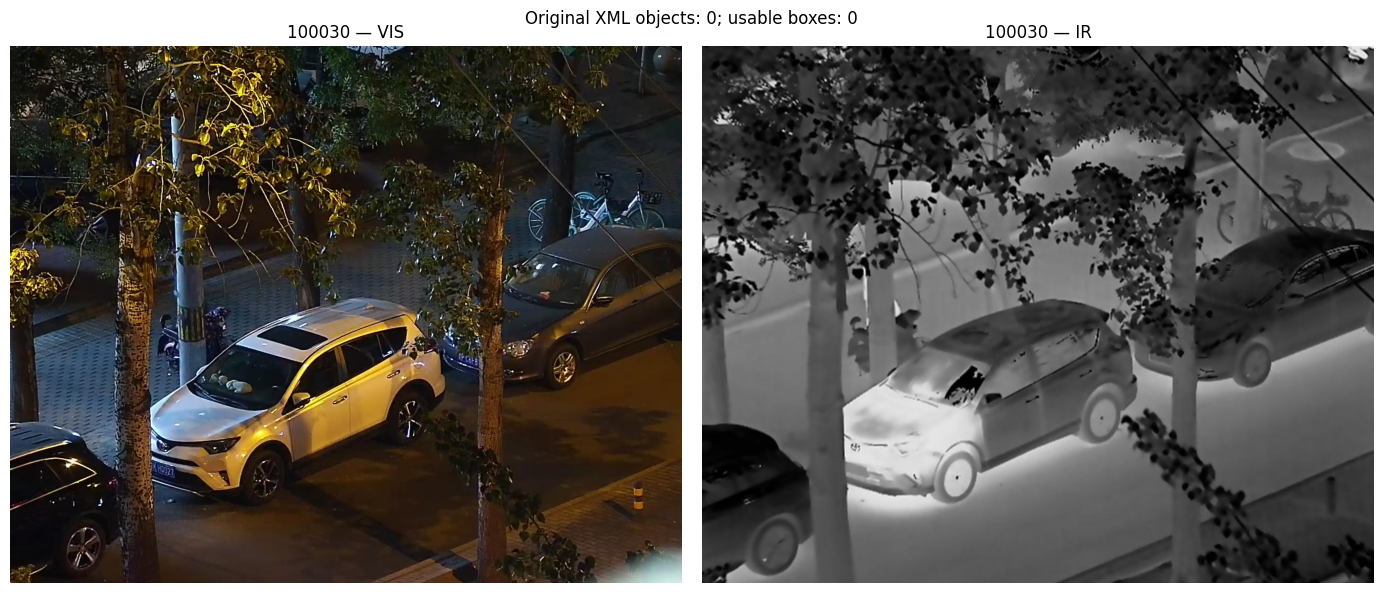

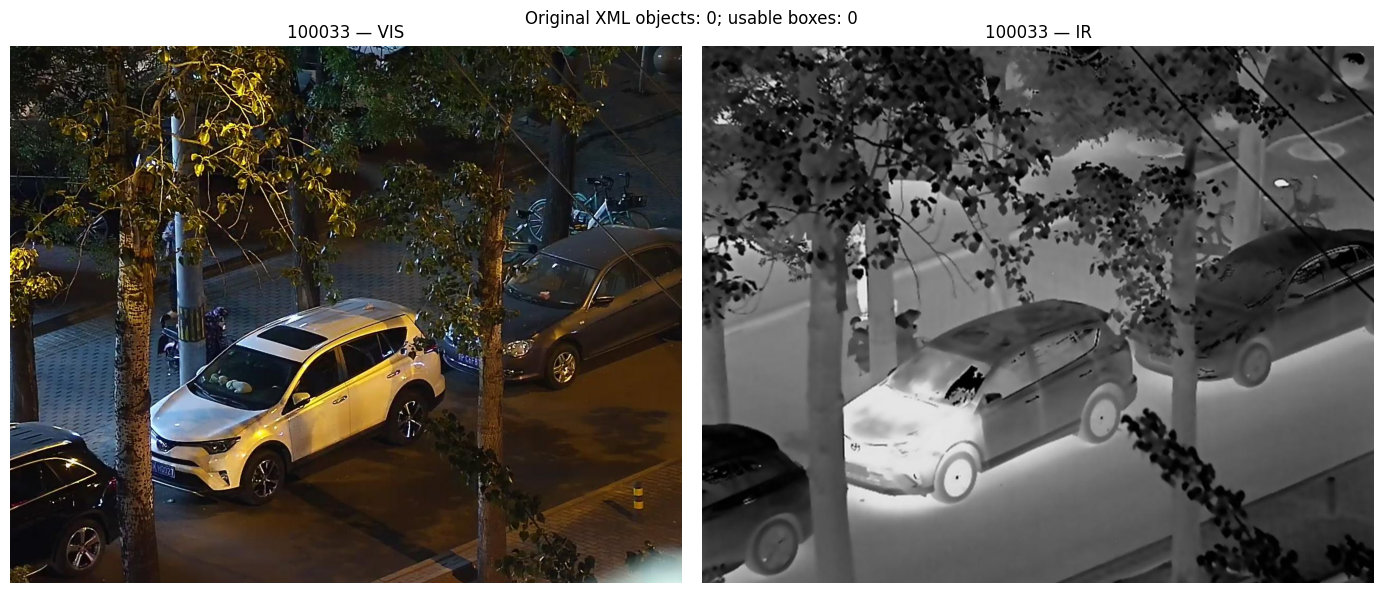

In [ ]:
from collections import Counter
import math
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from PIL import Image

class_counts = Counter()
invalid_boxes = []
empty_images = []
total_valid = 0

for pair_id in sorted(selected_ids):
    xml_root = ET.parse(annotations / f"{pair_id}.xml").getroot()

    with Image.open(ir_dir / f"{pair_id}.jpg") as image:
        width, height = image.size

    objects = xml_root.findall("object")
    valid_count = 0

    for obj in objects:
        name = obj.findtext("name", "").strip()
        class_counts[name] += 1

        box = obj.find("bndbox")
        coordinates = [
            float(box.findtext(key))
            for key in ["xmin", "ymin", "xmax", "ymax"]
        ]
        x1, y1, x2, y2 = coordinates

        valid = (
            all(math.isfinite(value) for value in coordinates)
            and 0 <= x1 < x2 <= width
            and 0 <= y1 < y2 <= height
        )

        if valid:
            valid_count += 1
        else:
            invalid_boxes.append((pair_id, name, coordinates))

    total_valid += valid_count

    if valid_count == 0:
        empty_images.append((pair_id, len(objects)))

print("Classes:", dict(class_counts))
print("Valid boxes:", total_valid)
print("Invalid boxes:", len(invalid_boxes))
print("Images with no valid boxes:", empty_images)

print("\nInvalid-box details:")
for entry in invalid_boxes:
    print(entry)

# Display the images with no valid boxes for visual review.
for pair_id, original_count in empty_images:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    for axis, folder, modality in [
        (axes[0], vis_dir, "VIS"),
        (axes[1], ir_dir, "IR"),
    ]:
        with Image.open(folder / f"{pair_id}.jpg") as image:
            axis.imshow(image.copy())
        axis.set_title(f"{pair_id} — {modality}")
        axis.axis("off")

    fig.suptitle(
        f"Original XML objects: {original_count}; usable boxes: 0"
    )
    plt.tight_layout()
    plt.show()

In [ ]:
from pathlib import Path
import hashlib
import json
import math
import shutil
import xml.etree.ElementTree as ET
import zipfile
from PIL import Image

repo = Path("/content/EO_IR_Capstone")
work = Path("/content/eo_ir_recovery")
dataset = work / "original/LLVIP"
shared_root = Path("/content/drive/MyDrive/EO_IR_Capstone")

# Preserve the original committed split; derive an explicitly filtered split.
original_train = (repo / "manifests/train_ids.txt").read_text().split()
original_val = (repo / "manifests/val_ids.txt").read_text().split()

excluded = {"100030", "100033"}

assert len(original_train) == 10030
assert len(original_val) == 1995
assert excluded <= set(original_train)
assert not excluded & set(original_val)
assert not set(original_train) & set(original_val)

train = [p for p in original_train if p not in excluded]
val = original_val[:]
included = sorted(set(train) | set(val))

assert len(train) == 10028
assert len(val) == 1995
assert len(included) == 12023

# Convert annotations before writing the archive.
labels = {}
discarded = []
box_count = 0

for pair_id in included:
    with Image.open(dataset / f"infrared/train/{pair_id}.jpg") as image:
        width, height = image.size

    with Image.open(dataset / f"visible/train/{pair_id}.jpg") as image:
        assert image.size == (width, height), pair_id

    root = ET.parse(dataset / f"Annotations/{pair_id}.xml").getroot()
    rows = []

    for obj in root.findall("object"):
        name = obj.findtext("name", "").strip()
        assert name == "person", (pair_id, name)

        box = obj.find("bndbox")
        coords = [
            float(box.findtext(key))
            for key in ["xmin", "ymin", "xmax", "ymax"]
        ]
        x1, y1, x2, y2 = coords

        valid = (
            all(math.isfinite(value) for value in coords)
            and 0 <= x1 < x2 <= width
            and 0 <= y1 < y2 <= height
        )

        if not valid:
            discarded.append({"pair_id": pair_id, "box": coords})
            continue

        rows.append(
            f"0 {(x1+x2)/(2*width):.6f} "
            f"{(y1+y2)/(2*height):.6f} "
            f"{(x2-x1)/width:.6f} {(y2-y1)/height:.6f}"
        )

    assert rows, f"Unexpected empty annotation: {pair_id}"
    labels[pair_id] = "\n".join(rows) + "\n"
    box_count += len(rows)

assert len(discarded) == 5, discarded
assert {x["pair_id"] for x in discarded} == {
    "020118", "020236", "090437", "091180", "170350"
}
assert box_count == 34130, box_count

split_info = {
    "seed": 42,
    "method": "Original committed prefix-group split; two training exclusions",
    "original_train_pairs": len(original_train),
    "original_val_pairs": len(original_val),
    "train_pairs": len(train),
    "val_pairs": len(val),
    "overlap": len(set(train) & set(val)),
    "excluded_train_ids": sorted(excluded),
}

inventory = {
    "source_archive": "LLVIP.zip",
    "included_pairs": len(included),
    "image_size_width_height": [1280, 1024],
    "label_boxes": box_count,
    "label_empty_images": 0,
    "discarded_invalid_boxes": discarded,
    "exclusion_reason": (
        "Original XML has zero objects; pedestrian-free status uncertain "
        "from visual review. Excluded from both modalities."
    ),
    "split": split_info,
}

archive_path = work / "llvip_milestone_recovered_v1.zip"

# Images are already compressed JPEGs; avoid expensive recompression.
image_bytes = sum(
    (dataset / modality / "train" / f"{p}.jpg").stat().st_size
    for p in included
    for modality in ["visible", "infrared"]
)
assert shutil.disk_usage(work).free > image_bytes + 512 * 1024**2, (
    "Insufficient local disk space to build the archive."
)

print("Building recovered archive...", flush=True)

with zipfile.ZipFile(
    archive_path, "w", compression=zipfile.ZIP_STORED, allowZip64=True
) as bundle:
    for index, pair_id in enumerate(included, start=1):
        for short, source in [("vis", "visible"), ("ir", "infrared")]:
            bundle.write(
                dataset / source / "train" / f"{pair_id}.jpg",
                f"eo_ir_data/{short}/images/{pair_id}.jpg",
            )
            bundle.writestr(
                f"eo_ir_data/{short}/labels/{pair_id}.txt",
                labels[pair_id],
            )

        if index % 2000 == 0:
            print(f"Packed {index}/{len(included)} pairs", flush=True)

    for short in ["vis", "ir"]:
        for split_name, ids in [("train", train), ("val", val)]:
            bundle.writestr(
                f"eo_ir_data/{short}_{split_name}.txt",
                "".join(f"./{short}/images/{p}.jpg\n" for p in ids),
            )

    manifest_contents = {
        "train_ids.txt": "\n".join(train) + "\n",
        "val_ids.txt": "\n".join(val) + "\n",
        "original_train_ids.txt": "\n".join(original_train) + "\n",
        "original_val_ids.txt": "\n".join(original_val) + "\n",
        "split_info.json": json.dumps(split_info, indent=2),
    }

    for name, text in manifest_contents.items():
        bundle.writestr(f"eo_ir_data/manifests/{name}", text)

    bundle.writestr(
        "eo_ir_data/inventory.json", json.dumps(inventory, indent=2)
    )

print("Checking recovered archive...", flush=True)
with zipfile.ZipFile(archive_path) as bundle:
    assert bundle.testzip() is None, "Recovered archive integrity failure"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

checksum = sha256_file(archive_path)

# Save separately from the existing prepared files.
destination = shared_root / "data/prepared/recovery_v1"
destination.mkdir(parents=True, exist_ok=True)

upload = destination / (archive_path.name + ".uploading")
saved_archive = destination / archive_path.name

print("Copying recovered archive to shared Drive...", flush=True)
shutil.copyfile(archive_path, upload)

print("Verifying the uploaded copy...", flush=True)
assert sha256_file(upload) == checksum, "Drive copy checksum mismatch"
upload.replace(saved_archive)

(destination / "llvip_milestone_recovered_v1.sha256").write_text(
    f"{checksum}  {archive_path.name}\n"
)
(destination / "inventory.json").write_text(
    json.dumps(inventory, indent=2)
)
(destination / "split_info.json").write_text(
    json.dumps(split_info, indent=2)
)

print("\nRECOVERY COMPLETE")
print("Archive:", saved_archive)
print("SHA-256:", checksum)
print("Training pairs:", len(train))
print("Validation pairs:", len(val))
print("Valid boxes:", box_count)
print("Discarded invalid boxes:", len(discarded))
print("Excluded training pairs:", sorted(excluded))

Building recovered archive...
Packed 2000/12023 pairs
Packed 4000/12023 pairs
Packed 6000/12023 pairs
Packed 8000/12023 pairs
Packed 10000/12023 pairs
Packed 12000/12023 pairs
Checking recovered archive...
Copying recovered archive to shared Drive...
Verifying the uploaded copy...

RECOVERY COMPLETE
Archive: /content/drive/MyDrive/EO_IR_Capstone/data/prepared/recovery_v1/llvip_milestone_recovered_v1.zip
SHA-256: 5c5274dabf94113d66bf86fc81cb86a2b71a0adfe2e19d5322c28d356b06e07e
Training pairs: 10028
Validation pairs: 1995
Valid boxes: 34130
Discarded invalid boxes: 5
Excluded training pairs: ['100030', '100033']


Cell 7: Persistent checkpoint and log folders

In [ ]:
RUN_DIRS = {
    "vis": f"{DRIVE_ROOT}/runs/vis_baseline",
    "ir":  f"{DRIVE_ROOT}/runs/ir_baseline",
}
for name, d in RUN_DIRS.items():
    os.makedirs(d, exist_ok=True)
    test = os.path.join(d, ".write_test")
    open(test, "w").write("ok"); os.remove(test)
    print(f"{name}: writable -> {d}")

vis: writable -> /content/drive/MyDrive/EO_IR_Capstone/runs/vis_baseline
ir: writable -> /content/drive/MyDrive/EO_IR_Capstone/runs/ir_baseline


Copy and extract prepared archive

In [ ]:
from pathlib import Path
import hashlib
import shutil
import zipfile

PREP_ZIP = Path(
    "/content/drive/MyDrive/EO_IR_Capstone/data/prepared/"
    "recovery_v1/llvip_milestone_recovered_v1.zip"
)
EXPECTED_SHA = (
    "5c5274dabf94113d66bf86fc81cb86a2b71"
    "a0adfe2e19d5322c28d356b06e07e"
)

local_zip = Path(
    "/content/eo_ir_recovery/llvip_milestone_recovered_v1.zip"
)
extract_to = Path("/content/eo_ir_recovery/verified_bundle")
DATA_ROOT = str(extract_to / "eo_ir_data")

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

if not local_zip.is_file():
    assert PREP_ZIP.is_file(), f"Missing shared archive: {PREP_ZIP}"
    local_zip.parent.mkdir(parents=True, exist_ok=True)
    print("Copying recovered archive from Drive...", flush=True)
    shutil.copyfile(PREP_ZIP, local_zip)

print("Checking local archive checksum...", flush=True)
assert sha256_file(local_zip) == EXPECTED_SHA, "Checksum mismatch"
print("Checksum OK")

with zipfile.ZipFile(local_zip) as archive:
    required_bytes = sum(item.file_size for item in archive.infolist())
    assert shutil.disk_usage(local_zip.parent).free > required_bytes, (
        "Insufficient local disk space for extraction."
    )
    extract_to.mkdir(parents=True, exist_ok=True)
    print("Extracting recovered data...", flush=True)
    archive.extractall(extract_to)

assert Path(DATA_ROOT).is_dir()
print("Extraction complete")
print("DATA_ROOT:", DATA_ROOT)
print("Contents:", sorted(p.name for p in Path(DATA_ROOT).iterdir()))

Checking local archive checksum...
Checksum OK
Extracting recovered data...
Extraction complete
DATA_ROOT: /content/eo_ir_recovery/verified_bundle/eo_ir_data
Contents: ['inventory.json', 'ir', 'ir_train.txt', 'ir_val.txt', 'manifests', 'vis', 'vis_train.txt', 'vis_val.txt']


Validate data inventory

In [ ]:
from pathlib import Path
import json
import sys

data_root = Path(DATA_ROOT)
inventory = json.loads((data_root / "inventory.json").read_text())

assert inventory["split"]["train_pairs"] == 10028
assert inventory["split"]["val_pairs"] == 1995
assert inventory["label_boxes"] == 34130
assert set(inventory["split"]["excluded_train_ids"]) == {
    "100030", "100033"
}

ids = {}

for modality in ["vis", "ir"]:
    for split in ["train", "val"]:
        list_file = data_root / f"{modality}_{split}.txt"
        entries = list_file.read_text().split()
        image_paths = [data_root / entry for entry in entries]
        pair_ids = [path.stem for path in image_paths]

        missing_images = [
            str(path) for path in image_paths if not path.is_file()
        ]
        missing_labels = [
            pair_id for pair_id in pair_ids
            if not (
                data_root / modality / "labels" / f"{pair_id}.txt"
            ).is_file()
        ]

        expected = 10028 if split == "train" else 1995
        assert len(entries) == expected
        assert len(set(pair_ids)) == expected
        assert not missing_images, missing_images[:5]
        assert not missing_labels, missing_labels[:5]

        ids[(modality, split)] = set(pair_ids)
        print(
            f"{modality}_{split}: {len(entries)} images; "
            "all images and labels present"
        )

assert ids[("vis", "train")] == ids[("ir", "train")]
assert ids[("vis", "val")] == ids[("ir", "val")]
assert not ids[("vis", "train")] & ids[("vis", "val")]
assert not {"100030", "100033"} & (
    ids[("vis", "train")] | ids[("vis", "val")]
)

print("\nMatching VIS/IR splits; no overlap; exclusions confirmed.")

# Exercise the installed detector's actual data loader.
YOLO_DIR = "/content/yolov5"
assert Path(YOLO_DIR).is_dir(), "Run the detector installation cell first."

sys.path.insert(0, YOLO_DIR)
from utils.dataloaders import LoadImagesAndLabels

for modality in ["vis", "ir"]:
    for split in ["train", "val"]:
        loaded = LoadImagesAndLabels(
            str(data_root / f"{modality}_{split}.txt"),
            img_size=640,
            batch_size=8,
            augment=False,
        )

        expected = len(ids[(modality, split)])
        assert len(loaded.im_files) == expected, (
            f"{modality}_{split}: loader retained "
            f"{len(loaded.im_files)} of {expected} images"
        )
        print(f"{modality}_{split}: detector data-loader check passed")

print("\nRECOVERED DATA VALIDATION COMPLETE")

vis_train: 10028 images; all images and labels present
vis_val: 1995 images; all images and labels present
ir_train: 10028 images; all images and labels present
ir_val: 1995 images; all images and labels present

Matching VIS/IR splits; no overlap; exclusions confirmed.
Scanning /content/eo_ir_recovery/verified_bundle/eo_ir_data/vis_train... 10028 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10028/10028 413.4it/s 24.3s
New cache created: /content/eo_ir_recovery/verified_bundle/eo_ir_data/vis_train.cache
vis_train: detector data-loader check passed
Scanning /content/eo_ir_recovery/verified_bundle/eo_ir_data/vis_val... 1995 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1995/1995 411.3it/s 4.8s
New cache created: /content/eo_ir_recovery/verified_bundle/eo_ir_data/vis_val.cache
vis_val: detector data-loader check passed
Scanning /content/eo_ir_recovery/verified_bundle/eo_ir_data/ir_train... 10028 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10028/10028 478.2it/s 21.0s
N

Create VIS and IR Dataset Configurations

In [ ]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys
import torch
import yaml

data_root = Path(DATA_ROOT)
yolo_dir = Path("/content/yolov5")
shared_root = Path("/content/drive/MyDrive/EO_IR_Capstone")

assert torch.cuda.is_available(), "A GPU runtime is required for this pilot."

expected_commit = "f9578796b8a64889aa9e66dc06914d19f40d338e"
actual_commit = subprocess.check_output(
    ["git", "-C", str(yolo_dir), "rev-parse", "HEAD"],
    text=True,
).strip()

assert actual_commit == expected_commit, (
    f"Detector revision differs from the tested version: {actual_commit}"
)

config_dir = shared_root / "configs/recovery_v1"
config_dir.mkdir(parents=True, exist_ok=True)

dataset_configs = {}

for modality in ["vis", "ir"]:
    config = {
        "path": str(data_root),
        "train": f"{modality}_train.txt",
        "val": f"{modality}_val.txt",
        "nc": 1,
        "names": ["person"],
    }

    path = config_dir / f"{modality}.yaml"
    path.write_text(yaml.safe_dump(config, sort_keys=False))
    dataset_configs[modality] = path

    print(f"\n{modality.upper()} configuration:")
    print(path.read_text())

settings = {
    "dataset_bundle": "llvip_milestone_recovered_v1.zip",
    "dataset_sha256": (
        "5c5274dabf94113d66bf86fc81cb86a2b71"
        "a0adfe2e19d5322c28d356b06e07e"
    ),
    "train_pairs": 10028,
    "val_pairs": 1995,
    "excluded_train_ids": ["100030", "100033"],
    "detector": "YOLOv5s",
    "yolov5_commit": actual_commit,
    "initial_weights": "yolov5s.pt",
    "image_size": 640,
    "batch_size": 8,
    "seed": 42,
    "workers": 2,
    "python": sys.version,
    "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "manifest_sha256": {
        split: hashlib.sha256(
            (data_root / f"manifests/{split}_ids.txt").read_bytes()
        ).hexdigest()
        for split in ["train", "val"]
    },
}

(config_dir / "experiment_settings.json").write_text(
    json.dumps(settings, indent=2)
)

print("Configurations and settings saved to:", config_dir)


VIS configuration:
path: /content/eo_ir_recovery/verified_bundle/eo_ir_data
train: vis_train.txt
val: vis_val.txt
nc: 1
names:
- person


IR configuration:
path: /content/eo_ir_recovery/verified_bundle/eo_ir_data
train: ir_train.txt
val: ir_val.txt
nc: 1
names:
- person

Configurations and settings saved to: /content/drive/MyDrive/EO_IR_Capstone/configs/recovery_v1


Run a two-epoch test to verify training works and measure how long real runs will take on our GPU

In [ ]:
import os
import time
from datetime import datetime, timezone

# Locate original pretrained weights used to initialize the detector
weights = yolo_dir / "yolov5s.pt"
assert weights.is_file(), (
    "Pretrained weights are missing. Run the setup notebook's "
    "pretrained inference smoke test first."
)

# save pilot outputs in shared Drive, separately from final baseline runs
pilot_project = shared_root / "runs/pilots"
#give this pilot a unique timestamp name
pilot_name = "vis_timing_" + datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S"
)
pilot_dir = pilot_project / pilot_name
pilot_dir.mkdir(parents=True, exist_ok=False)

# Build the command that launches YOLOv5 training
command = [
    sys.executable,
    "-u",
    str(yolo_dir / "train.py"),
    "--data", str(dataset_configs["vis"]),
    "--weights", str(weights),
    "--img", "640",
    "--batch-size", "8",
    "--epochs", "2",
    "--seed", "42",
    "--workers", "2",
    "--device", "0",
    "--project", str(pilot_project),
    "--name", pilot_name,
    "--exist-ok",
    "--save-period", "1",
]

# pass runtime env to training process and disable external experiment-tracking
#   services for this test run
environment = os.environ.copy()
environment["WANDB_MODE"] = "disabled"
environment["COMET_MODE"] = "DISABLED"

(pilot_dir / "launch_command.json").write_text(
    json.dumps(command, indent=2)
)

print("Pilot output folder:", pilot_dir, flush=True)
print("Starting two-epoch VIS pilot...", flush=True)

# launch training and wait for it to finish
start = time.perf_counter()
result = subprocess.run(
    command,
    cwd=str(yolo_dir),
    env=environment,
)
elapsed = time.perf_counter() - start

timing = {
    "return_code": result.returncode,
    "elapsed_seconds": elapsed,
    "elapsed_minutes": elapsed / 60,
    "planned_epochs": 2,
}
(pilot_dir / "timing.json").write_text(json.dumps(timing, indent=2))

assert result.returncode == 0, (
    "Pilot failed. Send the final error output before proceeding."
)

print("\nPILOT COMPLETE")
print(f"Total elapsed minutes: {elapsed / 60:.2f}")
print("Results CSV:", pilot_dir / "results.csv")
print("Checkpoints:", pilot_dir / "weights")

Pilot output folder: /content/drive/MyDrive/EO_IR_Capstone/runs/pilots/vis_timing_20261024_231438
Starting two-epoch VIS pilot...

PILOT COMPLETE
Total elapsed minutes: 13.96
Results CSV: /content/drive/MyDrive/EO_IR_Capstone/runs/pilots/vis_timing_20261024_231438/results.csv
Checkpoints: /content/drive/MyDrive/EO_IR_Capstone/runs/pilots/vis_timing_20261024_231438/weights


Check test run's recorded losses and metrics

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

# Use the completed pilot's saved results, even if notebook variables changed.
pilot_dir = Path(
    "/content/drive/MyDrive/EO_IR_Capstone/runs/pilots/"
    "vis_timing_20261024_231438"
)
results_file = pilot_dir / "results.csv"

assert results_file.is_file(), f"Results file missing: {results_file}"

# YOLOv5 CSV headings can contain padding; remove it before selecting columns.
results = pd.read_csv(results_file)
results.columns = results.columns.str.strip()

# A completed two-epoch pilot should have two recorded training rows.
assert len(results) == 2, (
    f"Expected two epochs, found {len(results)} recorded rows."
)

# Inspect training losses and the four detection metrics planned for reporting.
columns = [
    "epoch",
    "train/box_loss",
    "train/obj_loss",
    "train/cls_loss",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP_0.5",
    "metrics/mAP_0.5:0.95",
]

missing = [column for column in columns if column not in results.columns]
assert not missing, (
    f"Expected columns missing: {missing}. "
    f"Available columns: {list(results.columns)}"
)

# NaN or infinite values would require investigation before longer runs.
values = results[columns].to_numpy(dtype=float)
assert np.isfinite(values).all(), "Non-finite loss or metric found."

print("PILOT LOSSES AND METRICS")
print(results[columns].to_string(index=False))

# Display final detection metrics as percentages for easier interpretation.
print("\nFINAL PILOT METRICS")
for column in columns[4:]:
    print(f"{column}: {100 * results.iloc[-1][column]:.2f}%")

# Confirm that the expected checkpoints were actually persisted to shared Drive.
print("\nSAVED CHECKPOINTS")
for name in ["last.pt", "best.pt"]:
    checkpoint = pilot_dir / "weights" / name
    assert checkpoint.is_file(), f"Checkpoint missing: {checkpoint}"
    print(f"{name}: {checkpoint.stat().st_size / 1e6:.1f} MB")

PILOT LOSSES AND METRICS
 epoch  train/box_loss  train/obj_loss  train/cls_loss  metrics/precision  metrics/recall  metrics/mAP_0.5  metrics/mAP_0.5:0.95
     0        0.065487        0.035212               0            0.89289         0.64888          0.74764               0.36663
     1        0.048225        0.028617               0            0.88264         0.67524          0.77020               0.34075

FINAL PILOT METRICS
metrics/precision: 88.26%
metrics/recall: 67.52%
metrics/mAP_0.5: 77.02%
metrics/mAP_0.5:0.95: 34.08%

SAVED CHECKPOINTS
last.pt: 14.4 MB
best.pt: 14.4 MB
